<h2>Importowanie bibliotek oraz deklaracja stałych</h2>

In [24]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
import numpy as np
label_mapping = [
    'benign',
    'defacement',
    'phishing',
    'malware'
]

<h2>Inicjalizacja funkcji pomocniczych</h2>

In [16]:
def evaluate_model(prediction, Y_ground_truth):
    accuracy = accuracy_score(Y_ground_truth, prediction)
    f1 = f1_score(Y_ground_truth, prediction, average="macro")
    recall=recall_score(Y_ground_truth, prediction, average="macro", zero_division=0)
    precision=precision_score(Y_ground_truth, prediction, average="macro", zero_division=0)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro-F1: {f1:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")

    # Classification Report
    report = classification_report(
        Y_ground_truth,
        prediction,
        target_names=label_mapping,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).T

    # Pomijamy wiersze podsumowujące
    class_labels = [
        label for label in report_df.index
        if label not in ["accuracy", "macro avg", "weighted avg"]
    ]

    plt.figure(figsize=(9, 4))

    sns.heatmap(
        report_df.loc[
            class_labels,
            ["precision", "recall", "f1-score"]
        ],
        annot=True,
        fmt=".4f",
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    plt.title("Classification Report")
    plt.xlabel("Metric")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    labels = sorted(set(Y_ground_truth) | set(prediction))

    cm = confusion_matrix(
        Y_ground_truth,
        prediction,
        labels=labels
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_mapping,
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    plt.title("Confusion Matrix")
    plt.tight_layout()
    plt.show()

<h2>Załadowanie dataseta zawierającego cechy</h2>

In [4]:
df = pd.read_csv("./../data/urls_features.csv")

print("Liczba rekordów:", df.shape[0])
print("Liczba kolumn:", df.shape[1])

print("\nInformacje o kolumnach:")
df.info()

Liczba rekordów: 641013
Liczba kolumn: 33

Informacje o kolumnach:
<class 'pandas.DataFrame'>
RangeIndex: 641013 entries, 0 to 641012
Data columns (total 33 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   url                       641013 non-null  str    
 1   type                      641013 non-null  str    
 2   domain                    628882 non-null  str    
 3   tld                       628881 non-null  str    
 4   suffix                    628881 non-null  str    
 5   subdomain                 250634 non-null  str    
 6   url_length                641013 non-null  int64  
 7   domain_length             641013 non-null  int64  
 8   subdomain_length          641013 non-null  int64  
 9   suffix_length             641013 non-null  int64  
 10  host_length               641013 non-null  int64  
 11  path_length               641013 non-null  int64  
 12  arguments_url_ratio       641013 non-null  f

<h2>Wykonanie podziału zbioru na podzbiory treningowe, walidacyjne i testowe w stosunku 70/15/15</h2>

In [2]:
#from src.split_dataset import main
#main()

Train:      448709 (70.00%)
Validation: 96152 (15.00%)
Test:       96152 (15.00%)


<h2>Załadowanie podzbiorów oraz weryfikacja odpowiedniego rozkładu poszczególnych klas</h2>

In [5]:
df_train = pd.read_csv("./../data/train.csv")
df_val = pd.read_csv("./../data/validation.csv")
df_test = pd.read_csv("./../data/test.csv")

class_counts = pd.DataFrame({
    "Original": df["type"].value_counts(),
    "Train": df_train["type"].value_counts(),
    "Validation": df_val["type"].value_counts(),
    "Test": df_test["type"].value_counts()
})

display(class_counts)

class_distribution = pd.DataFrame({
    "Original": df["type"].value_counts(normalize=True),
    "Train": df_train["type"].value_counts(normalize=True),
    "Validation": df_val["type"].value_counts(normalize=True),
    "Test": df_test["type"].value_counts(normalize=True)
}) * 100

display(class_distribution.round(2))

,Original,Train,Validation,Test
type,,,,
benign,428181,299727,64227,64227
defacement,95308,66716,14296,14296
phishing,93879,65715,14082,14082
malware,23645,16551,3547,3547


,Original,Train,Validation,Test
type,,,,
benign,66.80,66.80,66.80,66.80
defacement,14.87,14.87,14.87,14.87
phishing,14.65,14.65,14.65,14.65
malware,3.69,3.69,3.69,3.69


<h2>Wydobycie macierzy cech oraz etykiet z podzbiorów</h2>
Do macierzy cech nie trafiają kolumny zawierające wartości tekstowe oraz etykiety

In [6]:
def get_features(df):
    return df[[c for c in df.columns if c not in ['url','type','domain','tld','suffix','subdomain','label']]]

#Utworzenie macierzy cech
X_train = get_features(df_train)
X_val = get_features(df_val)
X_test = get_features(df_test)

#Wydobycie etykiet
Y_train=df_train['label']
Y_val=df_val['label']
Y_test=df_test['label']



<h2>Wytrenowanie i ewaluacja modelu Random Forest stanowiącego baseline</h2>

Accuracy: 0.9664
Macro-F1: 0.9485
Precision: 0.9643
Recall: 0.9345


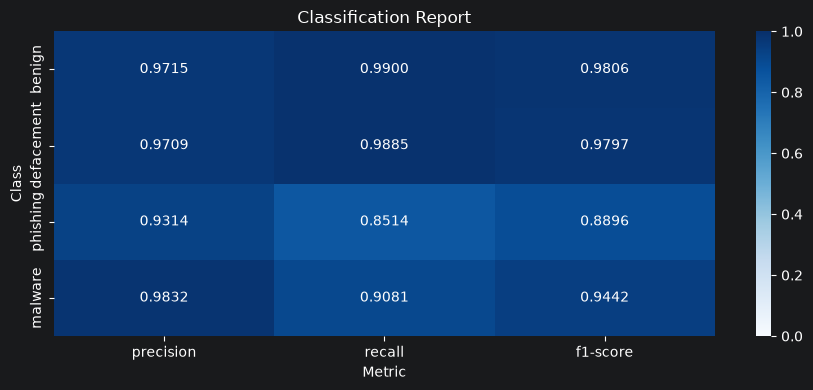

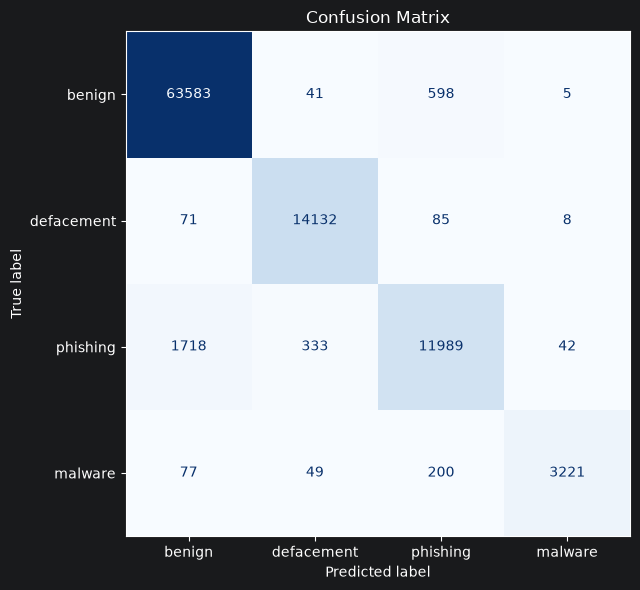

In [17]:
default_random_forest_model=RandomForestClassifier(random_state=42, n_jobs=-1)
default_random_forest_model.fit(X_train, Y_train)
predictions_rfm_b=default_random_forest_model.predict(X_val)
evaluate_model(predictions_rfm_b, Y_val)

<h2>Wytrenowanie i ewaluacja modelu Decision Tree stanowiącego baseline</h2>

Accuracy: 0.9481
Macro-F1: 0.9225
Precision: 0.9232
Recall: 0.9218


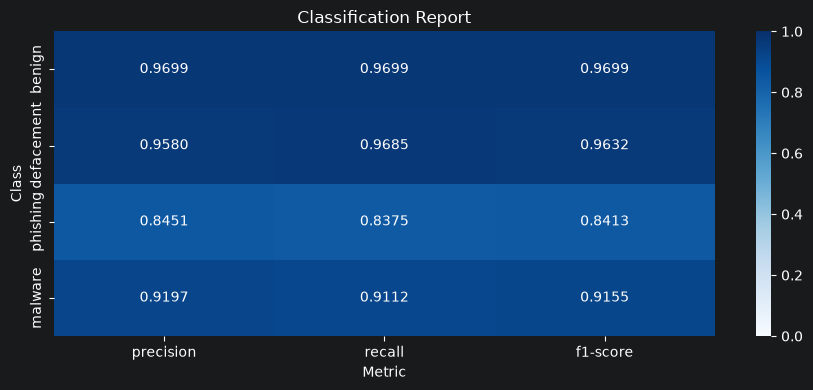

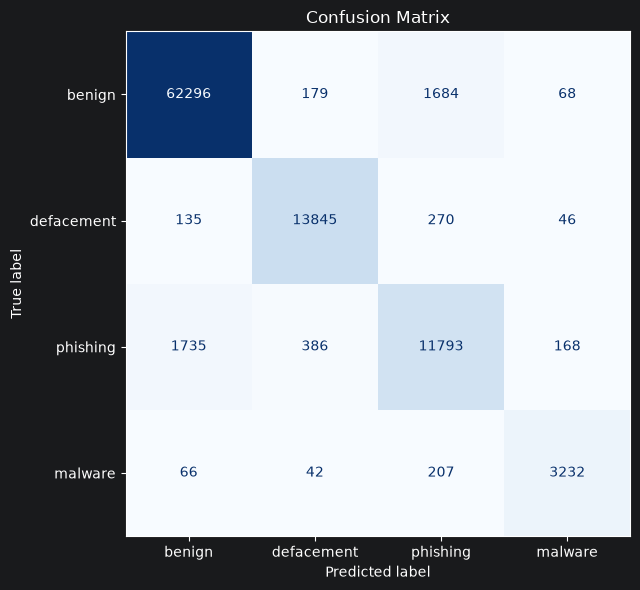

In [18]:
default_decision_tree_model=DecisionTreeClassifier(random_state=42)
default_decision_tree_model.fit(X_train, Y_train)
predictions_dtm_b=default_decision_tree_model.predict(X_val)
evaluate_model(predictions_dtm_b, Y_val)

<h2>Wytrenowanie i ewaluacja modelu Logistic Regression stanowiącego baseline</h2>

Accuracy: 0.8423
Macro-F1: 0.7499
Precision: 0.8182
Recall: 0.7165


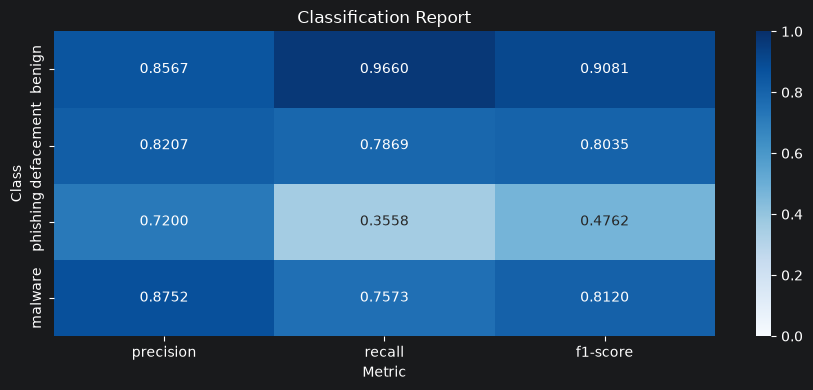

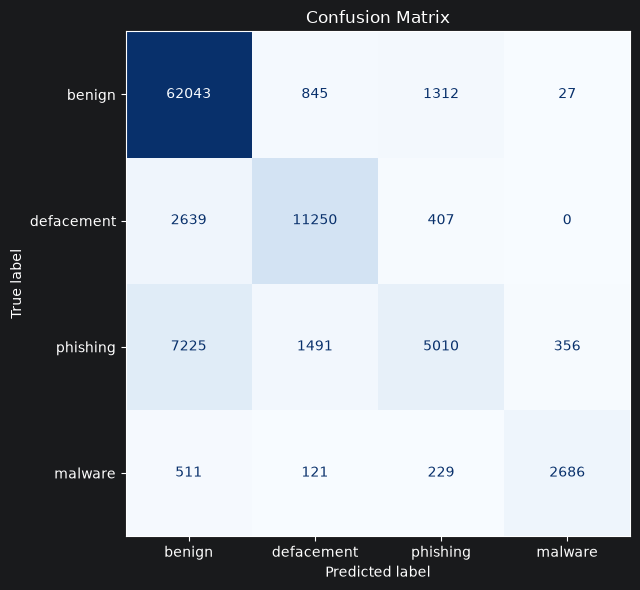

In [19]:
default_logistic_regression_model=make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42, max_iter=1000)
)
default_logistic_regression_model.fit(X_train, Y_train)
predictions_lr_b=default_logistic_regression_model.predict(X_val)
evaluate_model(predictions_lr_b, Y_val)

<h2>Sprawdzenie ważności cech na podstawie baseline Random Forest</h2>

,Importance
path_url_ratio,0.1070
symbol_count,0.0908
path_length,0.0868
dot_count,0.0753
suffix_length,0.0598
subdomain_length,0.0423
domain_entropy,0.0404
digit_count,0.0393
subdomain_entropy,0.0373
url_length,0.0365


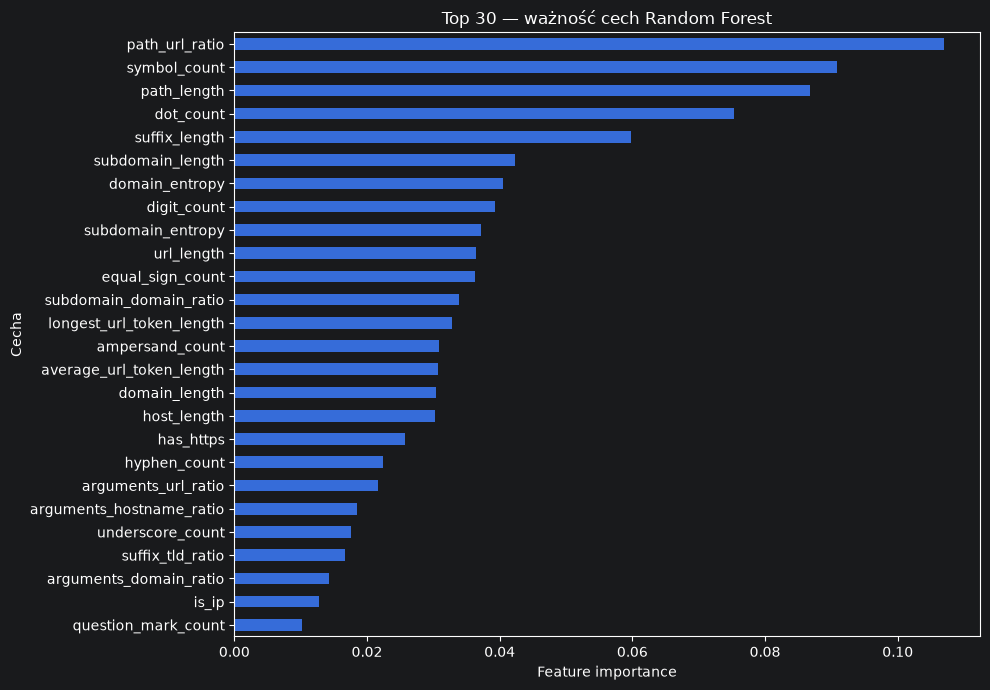

In [21]:
feature_importance = pd.Series(
    default_random_forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(
    feature_importance.to_frame(name="Importance").style.format(
        {"Importance": "{:.4f}"}
    ).background_gradient(cmap="Blues")
)

top_n = 30

feature_importance.head(top_n).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title(f"Top {top_n} — ważność cech Random Forest")
plt.xlabel("Feature importance")
plt.ylabel("Cecha")
plt.tight_layout()
plt.show()

<h2>Zbadanie permutation importance dla modelu Random Forest</h2>

,Feature,Importance Mean,Importance Std
0,symbol_count,0.28083,0.00137
1,path_url_ratio,0.14021,0.00071
2,dot_count,0.06323,0.00109
3,suffix_length,0.04032,0.00049
4,has_https,0.03823,0.00051
5,digit_count,0.03770,0.00130
6,hyphen_count,0.03439,0.00028
7,subdomain_entropy,0.02797,0.00008
8,path_length,0.02705,0.00033
9,underscore_count,0.01714,0.00040


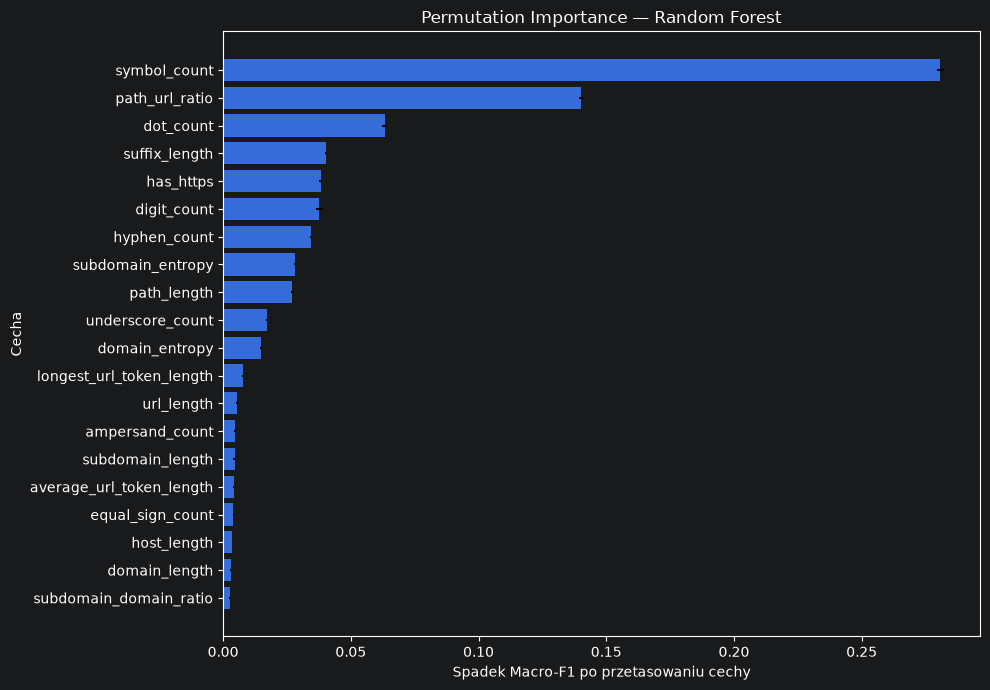

In [23]:
permutation_result = permutation_importance(
    default_random_forest_model,
    X_val,
    Y_val,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values(
    "Importance Mean",
    ascending=False
).reset_index(drop=True)

display(
    permutation_importance_df.style.format({
        "Importance Mean": "{:.5f}",
        "Importance Std": "{:.5f}"
    }).background_gradient(
        cmap="Blues",
        subset=["Importance Mean"]
    )
)

top_n = min(20, len(permutation_importance_df))

plot_data = permutation_importance_df.head(top_n).sort_values(
    "Importance Mean"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance Mean"],
    xerr=plot_data["Importance Std"]
)

plt.xlabel("Spadek Macro-F1 po przetasowaniu cechy")
plt.ylabel("Cecha")
plt.title("Permutation Importance — Random Forest")
plt.tight_layout()
plt.show()